# Jour 5 - Classification : `high_engagement`
Cible construite à partir de `vote_count` (seuil fixe 4 000). `vote_count` n'est jamais une feature.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
%matplotlib inline
from sklearn.model_selection import train_test_split
import src.models.classification as C

## 1. Données et cible

In [2]:
df = C.load_dataset(C.THRESHOLD)
print(df.shape)
df[C.TARGET].value_counts(normalize=True).round(3)

(2000, 53)


high_engagement
1    0.512
0    0.488
Name: proportion, dtype: float64

## 2. Variables : numériques, binaires, catégorielles, texte

In [3]:
groups = C.get_feature_groups(df)
feature_cols = groups['numeric'] + groups['binary'] + groups['categorical'] + [C.TEXT_COL]
C.assert_no_leakage(feature_cols)   # lève une erreur si vote_count & co. se glissent dans les features
{k: len(v) for k, v in groups.items()}

{'numeric': 10, 'binary': 22, 'categorical': 2}

## 3. Split stratifié
La stratification garde la même proportion de classes dans le train et le test.

In [4]:
X, y = df[feature_cols], df[C.TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=C.TEST_SIZE, stratify=y, random_state=C.RANDOM_STATE)
print(len(X_train), len(X_test), y_train.mean().round(3), y_test.mean().round(3))

1600 400 0.512 0.512


## 4. Le Pipeline (ColumnTransformer + modèle)

In [5]:
pipe = C.build_pipeline(C.get_models()['Logistic Regression'], groups)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the outp

## 5. Comparaison des 3 modèles + baseline

In [6]:
results, fitted, preds = C.run_models(X_train, X_test, y_train, y_test, groups)
results

,model,accuracy,precision,recall,f1,roc_auc,train_accuracy
0,Baseline (classe majoritaire),0.5125,0.5125,1.0000,0.6777,0.5000,0.5119
1,Logistic Regression,0.7225,0.7098,0.7756,0.7413,0.7982,0.8538
2,Random Forest,0.8100,0.7945,0.8488,0.8208,0.8807,1.0000
3,Linear SVM,0.6850,0.6820,0.7220,0.7014,0.7575,0.9950


## 6. Matrices de confusion et courbes ROC

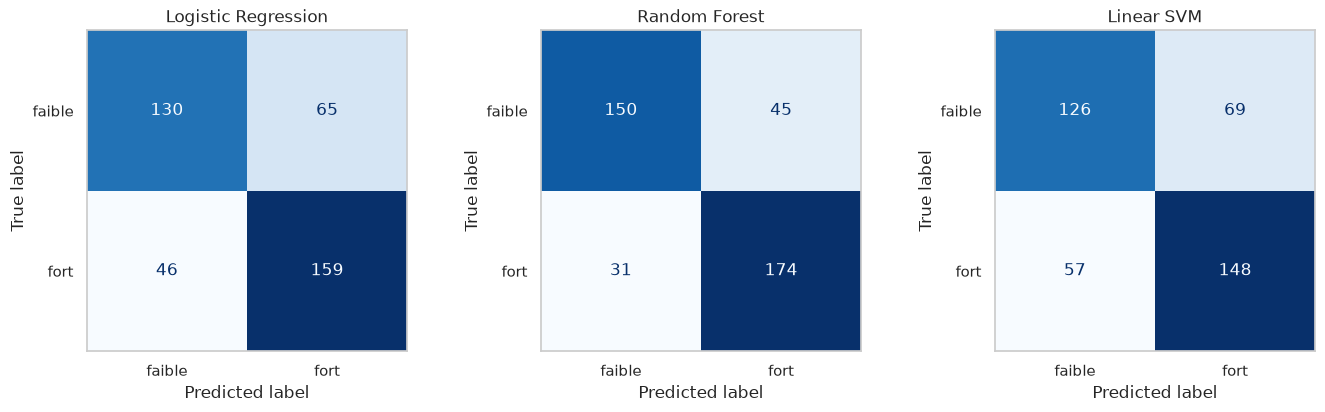

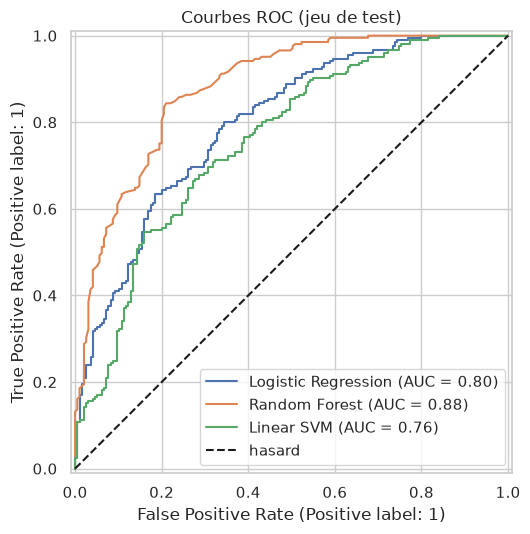

In [11]:
C.plot_confusions(preds, y_test, show=True)
C.plot_roc(fitted, X_test, y_test, show=True)

## 7. Variables influentes

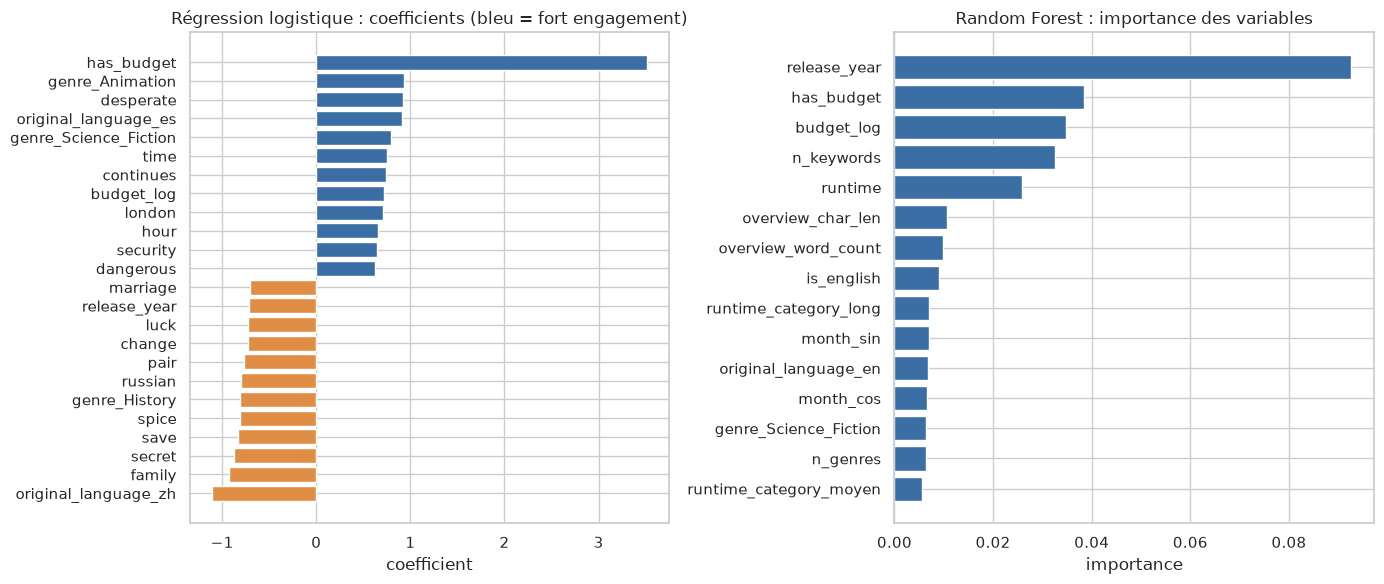

In [8]:
C.plot_importances(fitted, show=True)

## 8. Démonstration de leakage
On ajoute `popularity`, `vote_average` et `revenue` : le score monte, mais il est artificiel.

In [9]:
g2 = {**groups, 'numeric': groups['numeric'] + C.PROXY_FEATURES}
cols2 = g2['numeric'] + groups['binary'] + groups['categorical'] + [C.TEXT_COL]
Xa, Xb, ya, yb = train_test_split(df[cols2], y, test_size=C.TEST_SIZE, stratify=y, random_state=C.RANDOM_STATE)
leak, _, _ = C.run_models(Xa, Xb, ya, yb, g2, with_baseline=False)
leak[['model','accuracy','f1','roc_auc']]

,model,accuracy,f1,roc_auc
0,Logistic Regression,0.7725,0.7838,0.8643
1,Random Forest,0.8475,0.8565,0.9281
2,Linear SVM,0.7800,0.7925,0.8397


## 9. Sauvegarde complète
(ou `python src/models/classification.py`)

In [10]:
info = C.run_classification()
info['results']

,model,accuracy,precision,recall,f1,roc_auc,train_accuracy
0,Baseline (classe majoritaire),0.5125,0.5125,1.0000,0.6777,0.5000,0.5119
1,Logistic Regression,0.7225,0.7098,0.7756,0.7413,0.7982,0.8538
2,Random Forest,0.8100,0.7945,0.8488,0.8208,0.8807,1.0000
3,Linear SVM,0.6850,0.6820,0.7220,0.7014,0.7575,0.9950
